# Session 6 - Q1. Image Sharpening

Write a Python program to enhance image details using spatial-domain sharpening techniques:
1. High-pass filtering
2. Laplacian filtering
3. Unsharp masking
4. High-boost filtering

Display and compare the resulting images.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
image_path = "input.jpg"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError("Image could not be loaded.")

In [3]:
# High-pass filtering
high_pass_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

high_pass = cv2.filter2D(image, -1, high_pass_kernel)

# Laplacian filtering
laplacian = cv2.Laplacian(image, cv2.CV_64F)
laplacian = cv2.convertScaleAbs(laplacian)
laplacian_sharpened = cv2.add(image, laplacian)

In [4]:
# Unsharp masking
blurred = cv2.GaussianBlur(image, (5, 5), 0)
mask = cv2.subtract(image, blurred)
unsharp = cv2.add(image, mask)

# High-boost filtering
A = 1.5
high_boost = cv2.addWeighted(image, A, blurred, -(A - 1), 0)

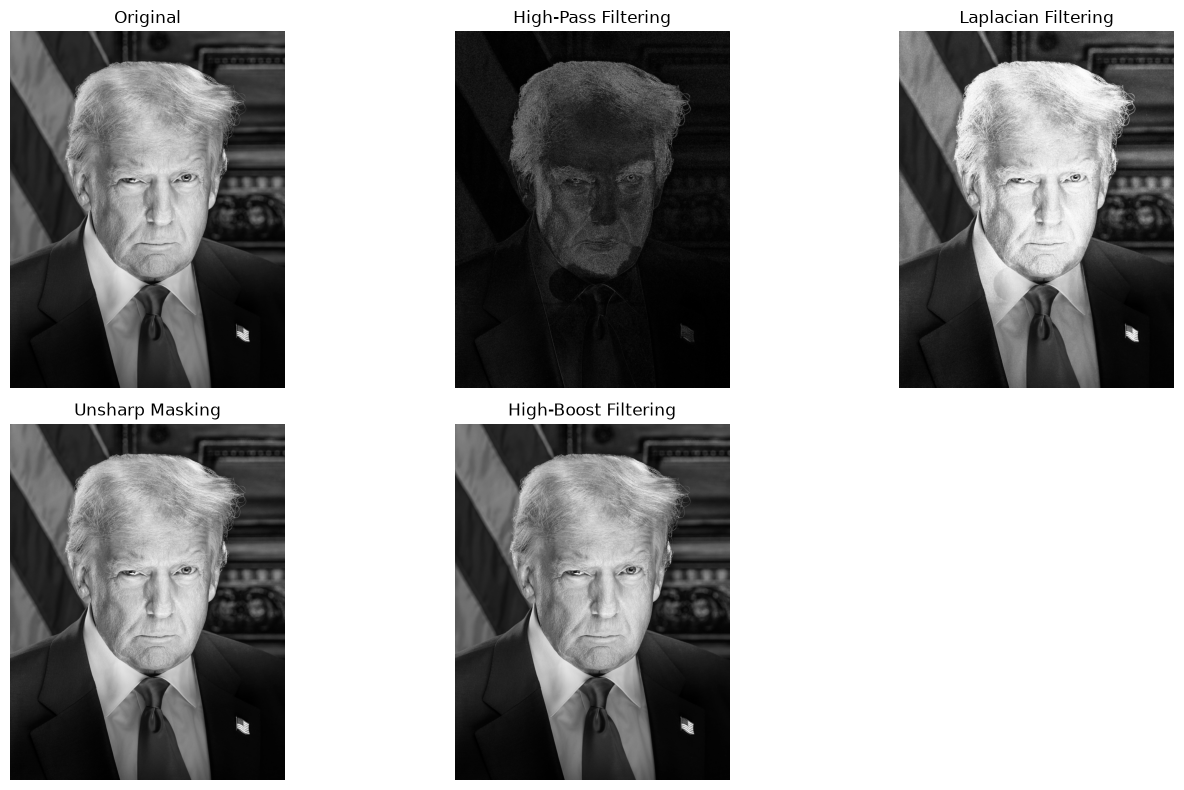

In [5]:
images = [image, high_pass, laplacian_sharpened, unsharp, high_boost]
titles = [
    "Original", "High-Pass Filtering", "Laplacian Filtering",
    "Unsharp Masking", "High-Boost Filtering"
]

plt.figure(figsize=(14, 8))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()